# Lab 8: Parsing

Omar Morales, Biel Altés

## Grammar

The sentence is `Lazy cats play with mice.` The grammar of the example only describes noun phrases, so we keep its rules and add what the new sentence needs:

- a start symbol `S` for a full sentence: a subject, a verb phrase and the final period,
- a verb phrase `VP`, with the verb alone or followed by a prepositional phrase,
- a prepositional phrase `PP`, made of a preposition and a noun phrase,
- the new words: `lazy`, `play`, `with` and `.`

The words of the grammar are in lowercase, so we lowercase the sentence before parsing. The period is kept as a token.

In [1]:
!pip install svgling

import re

import svgling  # draws the trees in the notebook
from nltk import CFG, BottomUpChartParser, BottomUpLeftCornerChartParser, LeftCornerChartParser

grammar = CFG.fromstring('''
  S     -> NP VP PUNCT
  NP    -> NNS | JJ NNS | NP CC NP
  VP    -> VBP | VBP PP
  PP    -> IN NP
  NNS   -> "cats" | "dogs" | "mice" | NNS CC NNS
  JJ    -> "big" | "small" | "lazy"
  CC    -> "and" | "or"
  VBP   -> "play"
  IN    -> "with"
  PUNCT -> "."
  ''')

sentence = 'Lazy cats play with mice.'
sent = re.findall(r'\w+|[^\w\s]', sentence.lower())
sent


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python3.14 -m pip install --upgrade pip


['lazy', 'cats', 'play', 'with', 'mice', '.']

## Parsing

`run` parses the sentence with one parser. It prints the number of edges, the edges in the order in which they were explored and the trees that cover the whole sentence. It also returns the chart and the trees, so we can draw the tree and compare the parsers later.

In an edge, the two numbers are the positions of the words it covers and `*` marks how much of the rule has been recognised. For example, `[0:1] NP -> JJ * NNS` means that the adjective was found between positions 0 and 1 and a noun is still missing.

In [2]:
def run(parser_class):
    chart = parser_class(grammar).chart_parse(sent)
    trees = list(chart.parses(grammar.start()))
    print(f'{parser_class.__name__}: {chart.num_edges()} edges, {len(trees)} tree(s)\n')
    for edge in chart.edges():
        print(edge)
    print()
    for tree in trees:
        print(tree)
    return chart, trees

charts = {}

### BottomUpChartParser

In [3]:
charts['BottomUpChartParser'], trees = run(BottomUpChartParser)

BottomUpChartParser: 55 edges, 1 tree(s)

[0:1] 'lazy'
[1:2] 'cats'
[2:3] 'play'
[3:4] 'with'
[4:5] 'mice'
[5:6] '.'
[0:0] JJ -> * 'lazy'
[0:1] JJ -> 'lazy' *
[0:0] NP -> * JJ NNS
[0:1] NP -> JJ * NNS
[1:1] NNS -> * 'cats'
[1:2] NNS -> 'cats' *
[1:1] NP -> * NNS
[1:1] NNS -> * NNS CC NNS
[0:2] NP -> JJ NNS *
[1:2] NP -> NNS *
[1:2] NNS -> NNS * CC NNS
[1:1] S  -> * NP VP PUNCT
[1:1] NP -> * NP CC NP
[1:2] S  -> NP * VP PUNCT
[1:2] NP -> NP * CC NP
[0:0] S  -> * NP VP PUNCT
[0:0] NP -> * NP CC NP
[0:2] S  -> NP * VP PUNCT
[0:2] NP -> NP * CC NP
[2:2] VBP -> * 'play'
[2:3] VBP -> 'play' *
[2:2] VP -> * VBP
[2:2] VP -> * VBP PP
[2:3] VP -> VBP *
[2:3] VP -> VBP * PP
[1:3] S  -> NP VP * PUNCT
[0:3] S  -> NP VP * PUNCT
[3:3] IN -> * 'with'
[3:4] IN -> 'with' *
[3:3] PP -> * IN NP
[3:4] PP -> IN * NP
[4:4] NNS -> * 'mice'
[4:5] NNS -> 'mice' *
[4:4] NP -> * NNS
[4:4] NNS -> * NNS CC NNS
[4:5] NP -> NNS *
[4:5] NNS -> NNS * CC NNS
[4:4] S  -> * NP VP PUNCT
[4:4] NP -> * NP CC NP
[3:5] PP -> I

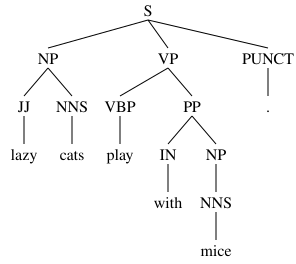

In [4]:
trees[0]

### BottomUpLeftCornerChartParser

In [5]:
charts['BottomUpLeftCornerChartParser'], trees = run(BottomUpLeftCornerChartParser)

BottomUpLeftCornerChartParser: 35 edges, 1 tree(s)

[0:1] 'lazy'
[1:2] 'cats'
[2:3] 'play'
[3:4] 'with'
[4:5] 'mice'
[5:6] '.'
[0:1] JJ -> 'lazy' *
[0:1] NP -> JJ * NNS
[1:2] NNS -> 'cats' *
[1:2] NP -> NNS *
[1:2] NNS -> NNS * CC NNS
[0:2] NP -> JJ NNS *
[0:2] S  -> NP * VP PUNCT
[0:2] NP -> NP * CC NP
[1:2] S  -> NP * VP PUNCT
[1:2] NP -> NP * CC NP
[2:3] VBP -> 'play' *
[2:3] VP -> VBP *
[2:3] VP -> VBP * PP
[0:3] S  -> NP VP * PUNCT
[1:3] S  -> NP VP * PUNCT
[3:4] IN -> 'with' *
[3:4] PP -> IN * NP
[4:5] NNS -> 'mice' *
[4:5] NP -> NNS *
[4:5] NNS -> NNS * CC NNS
[4:5] S  -> NP * VP PUNCT
[4:5] NP -> NP * CC NP
[3:5] PP -> IN NP *
[2:5] VP -> VBP PP *
[0:5] S  -> NP VP * PUNCT
[1:5] S  -> NP VP * PUNCT
[5:6] PUNCT -> '.' *
[0:6] S  -> NP VP PUNCT *
[1:6] S  -> NP VP PUNCT *

(S
  (NP (JJ lazy) (NNS cats))
  (VP (VBP play) (PP (IN with) (NP (NNS mice))))
  (PUNCT .))


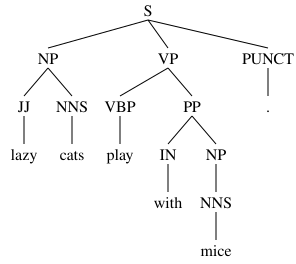

In [6]:
trees[0]

### LeftCornerChartParser

In [7]:
charts['LeftCornerChartParser'], trees = run(LeftCornerChartParser)

LeftCornerChartParser: 27 edges, 1 tree(s)

[0:1] 'lazy'
[1:2] 'cats'
[2:3] 'play'
[3:4] 'with'
[4:5] 'mice'
[5:6] '.'
[0:1] JJ -> 'lazy' *
[0:1] NP -> JJ * NNS
[1:2] NNS -> 'cats' *
[1:2] NP -> NNS *
[0:2] NP -> JJ NNS *
[0:2] S  -> NP * VP PUNCT
[1:2] S  -> NP * VP PUNCT
[2:3] VBP -> 'play' *
[2:3] VP -> VBP *
[2:3] VP -> VBP * PP
[3:4] IN -> 'with' *
[3:4] PP -> IN * NP
[4:5] NNS -> 'mice' *
[4:5] NP -> NNS *
[3:5] PP -> IN NP *
[2:5] VP -> VBP PP *
[0:5] S  -> NP VP * PUNCT
[1:5] S  -> NP VP * PUNCT
[5:6] PUNCT -> '.' *
[0:6] S  -> NP VP PUNCT *
[1:6] S  -> NP VP PUNCT *

(S
  (NP (JJ lazy) (NNS cats))
  (VP (VBP play) (PP (IN with) (NP (NNS mice))))
  (PUNCT .))


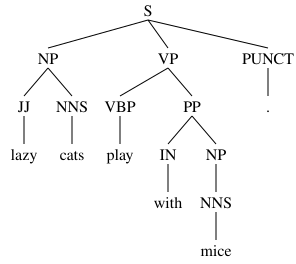

In [8]:
trees[0]

## Comparison

We compare the charts as sets of edges. For each pair of parsers we check that the smaller chart is contained in the bigger one and we print the edges that are missing.

In [9]:
edges = {name: [str(edge) for edge in chart.edges()] for name, chart in charts.items()}

print(f"{'Parser':<32}Edges")
for name, parser_edges in edges.items():
    print(f'{name:<32}{len(parser_edges)}')

def filtered(bigger, smaller):
    missing = [edge for edge in edges[bigger] if edge not in edges[smaller]]
    assert set(edges[smaller]) <= set(edges[bigger])
    print(f'\nIn {bigger} but not in {smaller}: {len(missing)}')
    for edge in missing:
        print(edge)

filtered('BottomUpChartParser', 'BottomUpLeftCornerChartParser')
filtered('BottomUpLeftCornerChartParser', 'LeftCornerChartParser')

Parser                          Edges
BottomUpChartParser             55
BottomUpLeftCornerChartParser   35
LeftCornerChartParser           27

In BottomUpChartParser but not in BottomUpLeftCornerChartParser: 20
[0:0] JJ -> * 'lazy'
[0:0] NP -> * JJ NNS
[1:1] NNS -> * 'cats'
[1:1] NP -> * NNS
[1:1] NNS -> * NNS CC NNS
[1:1] S  -> * NP VP PUNCT
[1:1] NP -> * NP CC NP
[0:0] S  -> * NP VP PUNCT
[0:0] NP -> * NP CC NP
[2:2] VBP -> * 'play'
[2:2] VP -> * VBP
[2:2] VP -> * VBP PP
[3:3] IN -> * 'with'
[3:3] PP -> * IN NP
[4:4] NNS -> * 'mice'
[4:4] NP -> * NNS
[4:4] NNS -> * NNS CC NNS
[4:4] S  -> * NP VP PUNCT
[4:4] NP -> * NP CC NP
[5:5] PUNCT -> * '.'

In BottomUpLeftCornerChartParser but not in LeftCornerChartParser: 8
[1:2] NNS -> NNS * CC NNS
[0:2] NP -> NP * CC NP
[1:2] NP -> NP * CC NP
[0:3] S  -> NP VP * PUNCT
[1:3] S  -> NP VP * PUNCT
[4:5] NNS -> NNS * CC NNS
[4:5] S  -> NP * VP PUNCT
[4:5] NP -> NP * CC NP


## Justification

| Parser | Edges |
|---|---|
| BottomUpChartParser | 55 |
| BottomUpLeftCornerChartParser | 35 |
| LeftCornerChartParser | 27 |

**Which parser is the most efficient for parsing the sentence?**

The three parsers give the same tree, and it is the only one, so the sentence is not ambiguous with our grammar. What changes is the number of edges they need. The most efficient is the `LeftCornerChartParser` with 27 edges, about half of the 55 of the `BottomUpChartParser`. Six edges in each chart are just the words of the sentence.

**Which edges are filtered out by each parser and why?**

The `BottomUpChartParser` does not filter anything. When it completes a constituent, it first adds an empty edge for every rule that starts with it, such as `[0:0] NP -> * JJ NNS` after finding the adjective, and then moves the dot in a second step. The `BottomUpLeftCornerChartParser` does both steps together and creates `[0:1] NP -> JJ * NNS` directly. This removes the 20 empty edges (the ones of the form `[i:i] A -> * ...`). The other 35 edges are the same in both charts, so the empty edges were only extra work.

The `LeftCornerChartParser` removes 8 more edges because it also looks at the next word. It only adds an edge if that word can start the symbol the edge is waiting for. Five of the removed edges come from the coordination rules of the original grammar: `NNS -> NNS * CC NNS` at `[1:2]` and `[4:5]`, and `NP -> NP * CC NP` at `[0:2]`, `[1:2]` and `[4:5]`. They wait for a conjunction, but after `cats` comes `play` and after `mice` comes the period. Two more are `S -> NP VP * PUNCT` at `[0:3]` and `[1:3]`. Here the verb phrase is only `play` and the edge waits for the period, but the next word is `with`. The last one is `S -> NP * VP PUNCT` at `[4:5]`, which takes `mice` as a subject and waits for a verb, but the sentence ends there.

Even so, the `LeftCornerChartParser` keeps some edges that are not used in the tree. The `S` edges at `[1:2]`, `[1:5]` and `[1:6]` read `cats play with mice.` as a sentence and leave `lazy` out. The parser only checks the word on the right, so it cannot know that a sentence should start at position 0. A top-down parser would be needed to avoid them.